# AH2179 Traffic project — A1: ALL-day data — cleaning, EDA, traffic regimes, features

Same corridor and pipeline as notebooks 01/02, but with the **24-hour files** (`dataset_for_traffic_project_assignment_ALLday`).

Why: in the morning files portal 55.620 has only 17 congested 5-min intervals (4 days) in training, far too few to learn congestion.
The ALL-day files contain the afternoon peak, where the corridor is congested almost every workday — thousands of congested
intervals. That makes it possible to (1) study the congested branch of the fundamental diagram properly and
(2) train separate free-flow / congested models (notebook A2).

Everything carries over from notebook 01: UTC → local time correction for the <4000 sensors, zero-flow vs outage rule,
lane imputation, 5-min bins stamped at bin end, causal gap filling for features only, statistics fitted on training only.
New here: the window is 00:00–24:00 local, features run **across midnight**, plus density and regime features.

**Leakage guards (section 4 tests them):**
* **Causal inputs, hindsight targets.** Every raw file is cleaned twice. The model *inputs* come from a real-time (causal) cleaning
  that at time t only uses data up to t. The *targets* (and the EDA) come from the hindsight cleaning, which may look at the whole gap
  — the truth is measured afterwards, so that is allowed there.
* **No statistic sees validation or test data.** Lane shares/profiles and the regime boundaries are fitted on the train split
  (before 2021-11-15). The historical-average input is built in two stages: for train/validation rows from the train split only,
  **out-of-fold** for training rows (the average for a row comes from the other weeks, so it never contains its own target);
  for the final refit on all of 2021 (`features_full`) from all 2021 days, again out-of-fold; 2022 rows use the full 2021 profile.
* Train rows are those whose *target* lies before 2021-11-15, so no training target falls in the validation period.

> ⚠️ **The ALL-day 2022 files are a different split of 2022 than the morning files.** ALL-day `evaluation` has 80 days and
> `final_evaluation` 101 days (no overlap between them), but ~half of the ALL-day *final* days are *morning evaluation* days and
> vice versa. Within this A-series only the ALL-day files are used, so the split stays clean — just don't mix results across the two series.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import gc, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl, joblib
import traffic_prep as tp
tp.set_window(0, 24 * 60)                      # ALL-day window, local time

DATA = Path("../dataset_for_traffic_project_assignment_ALLday")
OUT = Path("../processed_allday"); OUT.mkdir(exist_ok=True)
FIG = Path("../figures_allday"); FIG.mkdir(exist_ok=True)
RES_MIN, HORIZON_MIN = 5, 15
VAL_START = "2021-11-15"
SPLITS = ["training", "evaluation", "final_evaluation"]

PCOL = {k: mpl.colormaps["viridis"](i / 7 * 0.9) for i, k in enumerate(tp.PORTALS_DOWNSTREAM)}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)
qcols = [f"q_{tp.PORTAL_COL[k]}" for k in tp.PORTALS_DOWNSTREAM]
vcols = [f"v_{tp.PORTAL_COL[k]}" for k in tp.PORTALS_DOWNSTREAM]

## 1. Cleaning and aggregation (statistics fitted on the train split)

In [2]:
raw_tr = tp.load_raw(DATA / "training_dataset.csv")
lane_stats = tp.fit_lane_stats(raw_tr[raw_tr["date"] < VAL_START])      # train split only
lane_stats.to_json(OUT / "lane_stats.json")
portal, portal_c, report = {}, {}, {}
for s in SPLITS:
    raw = raw_tr if s == "training" else tp.load_raw(DATA / f"{s}_dataset.csv")
    lg, report[s] = tp.clean_lane_data(raw, lane_stats)                  # hindsight -> targets + EDA
    report[s]["days"] = len(lg.dates)
    portal[s] = tp.aggregate_portal(lg, lane_stats, res=f"{RES_MIN}min")
    lgc, _ = tp.clean_lane_data(raw, lane_stats, causal=True)            # causal (real-time) -> model inputs
    portal_c[s] = tp.aggregate_portal(lgc, lane_stats, res=f"{RES_MIN}min")
    portal[s].to_pickle(OUT / f"portal_{RES_MIN}min_{s}.pkl"); portal_c[s].to_pickle(OUT / f"portal_{RES_MIN}min_{s}_causal.pkl")
    del raw, lg, lgc; gc.collect()
days_chk = np.sort(raw_tr["date"].unique())[40:44]                 # 4 days kept for the leakage test (section 4)
raw_chk = raw_tr[raw_tr["date"].isin(days_chk)].reset_index(drop=True)
del raw_tr; gc.collect()
rep = pd.DataFrame(report)
g = rep.loc["grid_rows"]
for k in ["zero_filled", "outage", "sensor_day_missing"]:
    rep.loc[f"{k} (% of grid)"] = (rep.loc[k] / g * 100).round(2)
rep.loc["portal bins NaN (%)"] = [round(portal[s].flow_vph_obs.isna().mean() * 100, 2) for s in SPLITS]
rep.loc["causal ≠ hindsight flow (% of bins)"] = [round(float((~np.isclose(portal[s].flow_vph_obs, portal_c[s].flow_vph_obs, equal_nan=True)).mean() * 100), 2)
                                                  for s in SPLITS]
rep

,training,evaluation,final_evaluation
raw_rows,7469641.00,2737037.00,3449240.00
corrupt_rows_flow_nan,180.00,22.00,157.00
invalid_speed_set_nan,665.00,311.00,222.00
observed,7469461.00,2737015.00,3449083.00
zero_filled,656073.00,239028.00,308718.00
outage,610766.00,226495.00,301402.00
sensor_day_missing,200160.00,138240.00,158400.00
corrupt,180.00,22.00,157.00
grid_rows,8936640.00,3340800.00,4217760.00
days,214.00,80.00,101.00


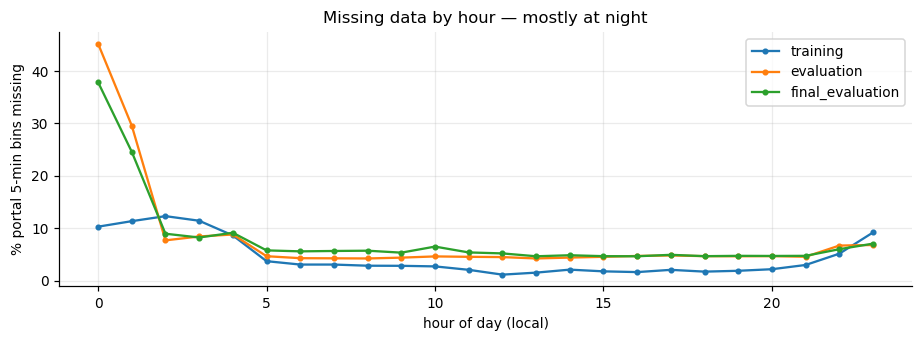

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))
for s in SPLITS:
    p = portal[s]; h = (p.minute_end - 5) // 60
    ax.plot(p.flow_vph_obs.isna().groupby(h).mean() * 100, "o-", ms=3, label=s)
ax.set(xlabel="hour of day (local)", ylabel="% portal 5-min bins missing", title="Missing data by hour — mostly at night")
ax.legend(); save(fig, "A1_missing_by_hour"); plt.show()

Missing data is concentrated at night (22:00–04:00). Night-time lane or carriageway closures for maintenance are common on
Essingeleden; a closed lane reports nothing and is (correctly) treated as *unknown*, not as zero flow. This does not affect the
daytime prediction task, and XGBoost / the imputer handle the remaining gaps.

## 2. Exploratory analysis over 24 hours

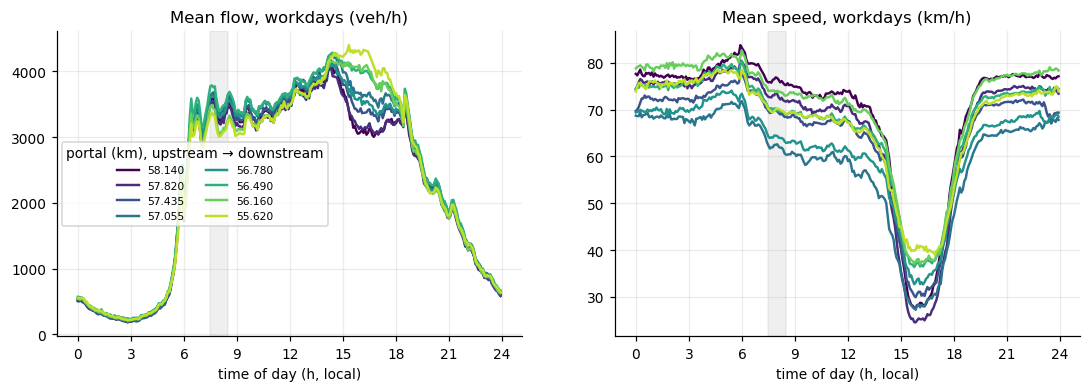

In [4]:
wide_obs = {s: tp.to_wide(p, observed=True) for s, p in portal.items()}      # hindsight, un-filled: targets + EDA
W = wide_obs["training"].copy()
W["tod"] = (W.index - pd.Timedelta(minutes=RES_MIN)).hour + (W.index - pd.Timedelta(minutes=RES_MIN)).minute / 60   # bin start
W["dtype"] = tp.day_type(pd.Series(W.index - pd.Timedelta(minutes=RES_MIN), index=W.index))
wd = W[W.dtype == "workday"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for k, q, v in zip(tp.PORTALS_DOWNSTREAM, qcols, vcols):
    ax[0].plot(wd.groupby("tod")[q].mean(), color=PCOL[k], lw=1.6, label=f"{k:.3f}")
    ax[1].plot(wd.groupby("tod")[v].mean(), color=PCOL[k], lw=1.6)
for a in ax:
    a.axvspan(7.5, 8.5, color="grey", alpha=.12); a.set_xticks(range(0, 25, 3)); a.set_xlabel("time of day (h, local)")
ax[0].set(title="Mean flow, workdays (veh/h)"); ax[1].set(title="Mean speed, workdays (km/h)")
ax[0].legend(title="portal (km), upstream → downstream", fontsize=7, ncol=2)
save(fig, "A1_daily_profiles_24h"); plt.show()

The southbound direction has a modest morning peak but a **long, heavy afternoon peak** (≈ 13:00–18:00) with a clear speed
collapse — this is where congestion lives. The grey band is the 07:30–08:30 benchmark window of the assignment.

### 2.1 Traffic regimes from the fundamental diagram
Flow alone cannot separate the regimes — the same flow occurs free-flowing and congested. Speed can: at every portal the 5-min
speed distribution is **bimodal** (narrow free-flow mode at 65–80 km/h, broad congested mode at 20–40 km/h). `tp.RegimeModel`
splits the fundamental diagram into two clusters at the **antimode** v* — the minimum of the kernel-smoothed speed density between the
two modes — fitted per portal on training data only. (A 2-D Gaussian mixture on speed and density was tried first, but its wide
congested component also claimed implausibly high speeds in the tails, so the simpler monotone rule is used.)
Density k = q / v (veh/km) is added as a feature: at equal flow it is ~4× higher in congestion.

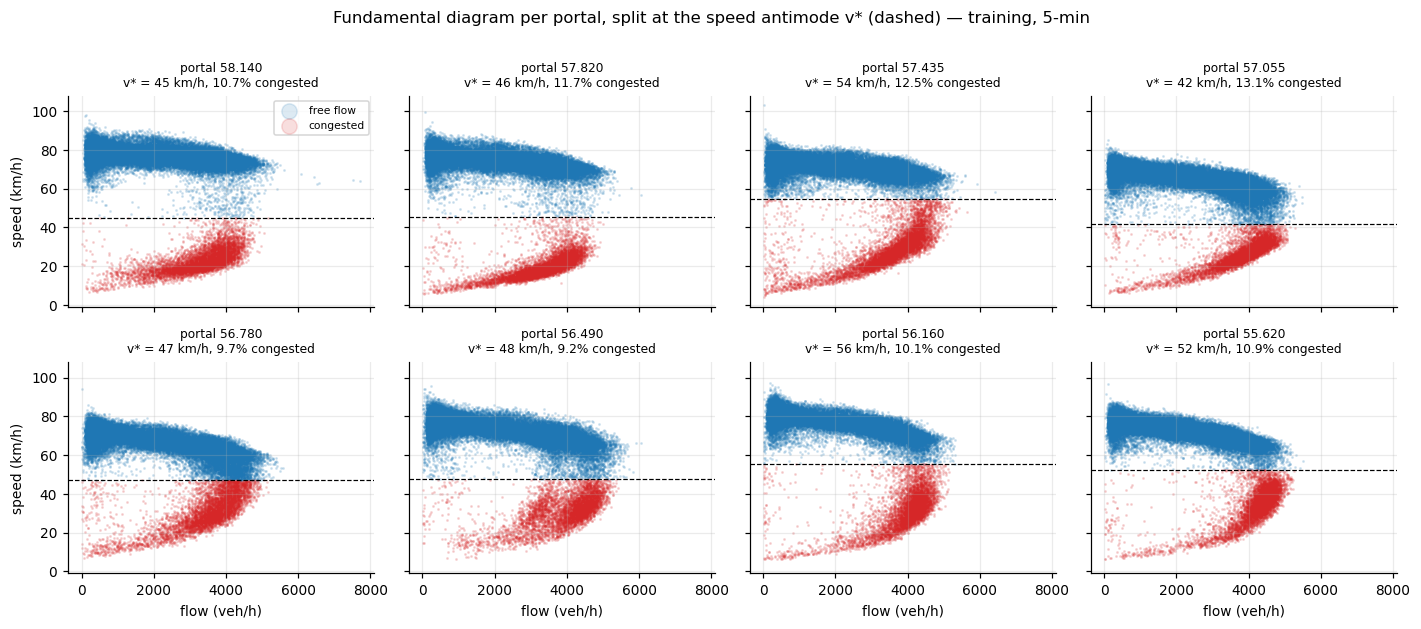

,free-flow mode (km/h),congested mode (km/h),boundary v* (km/h),share congested,capacity ≈ 99th pct flow (veh/h),mean density free / congested (veh/km)
58.140,77.5,19.5,45.0,0.109,4632,28 / 143
57.820,75.0,17.5,45.5,0.121,4585,29 / 169
57.435,71.5,29.5,54.5,0.129,4692,30 / 123
57.055,64.0,31.0,41.5,0.136,4728,35 / 144
56.780,68.5,29.5,47.0,0.096,4668,34 / 112
56.490,73.0,31.5,47.5,0.092,4992,32 / 128
56.160,77.5,31.0,55.5,0.102,4644,28 / 129
55.620,71.0,37.0,52.5,0.11,4752,30 / 126


In [5]:
reg = tp.RegimeModel().fit(portal["training"][portal["training"]["date"] < VAL_START])      # train split only
joblib.dump(reg, OUT / "regime_model.joblib")
fig, axs = plt.subplots(2, 4, figsize=(13, 5.6), sharex=True, sharey=True)
summary = {}
for a, k in zip(axs.flat, tp.PORTALS_DOWNSTREAM):
    p = tp.PORTAL_COL[k]
    x = W[[f"q_{p}", f"v_{p}"]].dropna()
    pr = reg.proba(p, x[f"q_{p}"], x[f"v_{p}"])
    c = pr >= 0.5
    a.scatter(x[f"q_{p}"][~c], x[f"v_{p}"][~c], s=1, alpha=.15, color="C0", label="free flow", rasterized=True)
    a.scatter(x[f"q_{p}"][c], x[f"v_{p}"][c], s=1, alpha=.15, color="C3", label="congested", rasterized=True)
    a.axhline(reg.vstar[p], color="k", lw=.8, ls="--")
    a.set_title(f"portal {k:.3f}\nv* = {reg.vstar[p]:.0f} km/h, {c.mean():.1%} congested", fontsize=8)
    kk = x[f"q_{p}"] / x[f"v_{p}"]
    summary[k] = {**{n: round(val, 3 if "share" in n else 1) for n, val in reg.info[p].items()},
                  "capacity ≈ 99th pct flow (veh/h)": int(np.nanpercentile(x[f"q_{p}"], 99)),
                  "mean density free / congested (veh/km)": f"{kk[~c].mean():.0f} / {kk[c].mean():.0f}"}
for a in axs[1]: a.set_xlabel("flow (veh/h)")
for a in axs[:, 0]: a.set_ylabel("speed (km/h)")
axs[0, 0].legend(markerscale=10, fontsize=7)
fig.suptitle("Fundamental diagram per portal, split at the speed antimode v* (dashed) — training, 5-min", y=1.01)
fig.tight_layout(); save(fig, "A1_fundamental_diagram_regimes"); plt.show()
pd.DataFrame(summary).T

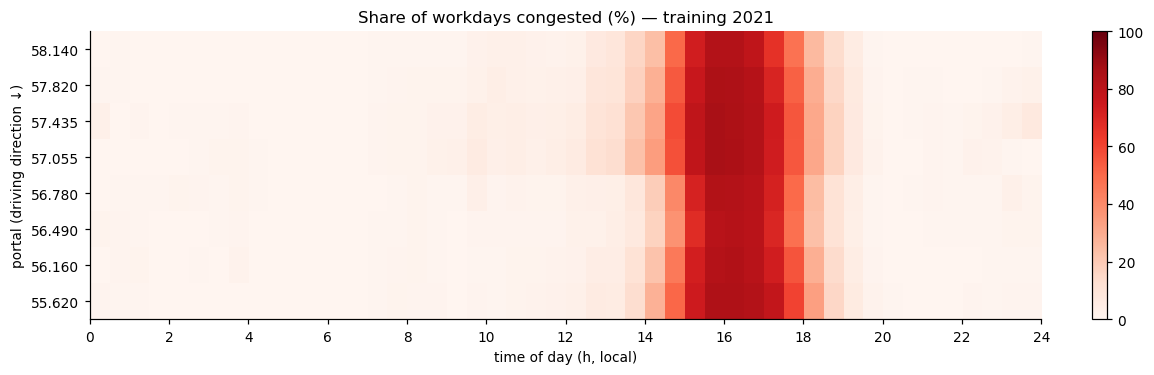

In [6]:
# how often is each portal congested, by time of day (workdays, training)?
cong = pd.DataFrame({tp.PORTAL_COL[k]: reg.proba(tp.PORTAL_COL[k], wd[f"q_{tp.PORTAL_COL[k]}"], wd[f"v_{tp.PORTAL_COL[k]}"]) >= 0.5
                     for k in tp.PORTALS_DOWNSTREAM}, index=wd.index)
share = cong.groupby(wd.tod.values // 0.5 * 0.5).mean().T * 100
fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(share, aspect="auto", cmap="Reds", vmin=0, vmax=100, extent=[0, 24, 7.5, -.5])
ax.set_yticks(range(8), [f"{k:.3f}" for k in tp.PORTALS_DOWNSTREAM]); ax.set_xticks(range(0, 25, 2)); ax.grid(False)
ax.set(xlabel="time of day (h, local)", ylabel="portal (driving direction ↓)",
       title="Share of workdays congested (%) — training 2021")
fig.colorbar(im, ax=ax, fraction=.02); save(fig, "A1_congestion_frequency"); plt.show()

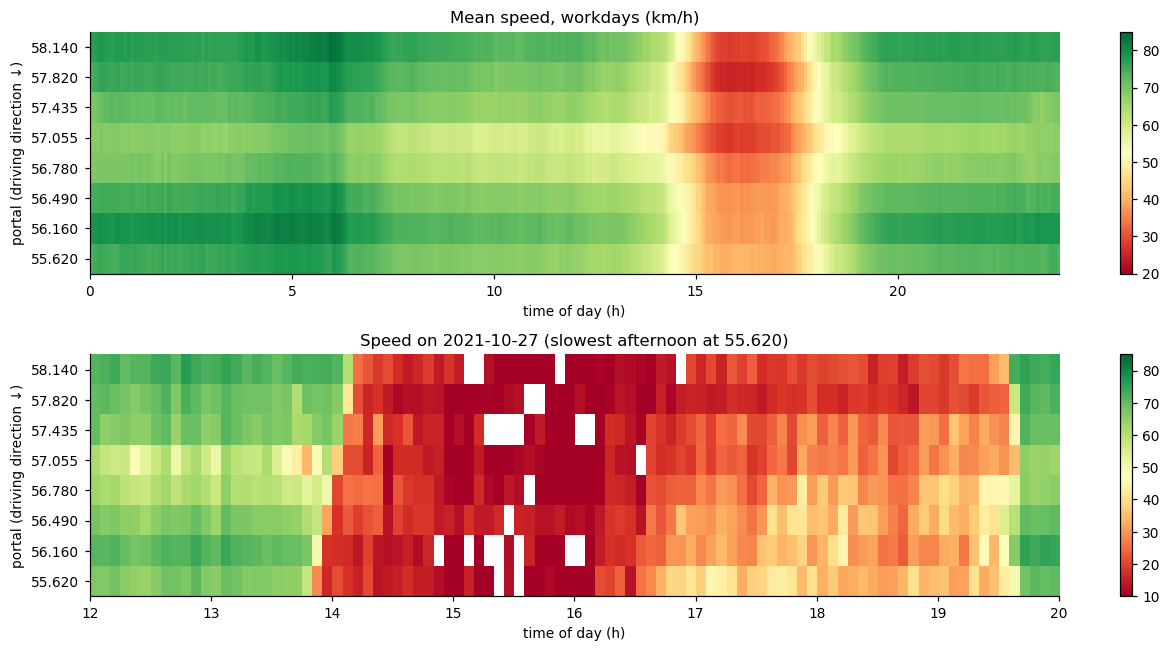

In [7]:
# space-time diagram: mean workday speed over 24 h, and one congested afternoon
def spacetime(df, prefix, ax, cmap, title, vmin=None, vmax=None):
    cols = [f"{prefix}_{tp.PORTAL_COL[k]}" for k in tp.PORTALS_DOWNSTREAM]
    m = df.groupby("tod")[cols].mean().T
    im = ax.imshow(m, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, extent=[m.columns.min(), m.columns.max() + 1 / 12, 7.5, -.5])
    ax.set_yticks(range(8), [f"{k:.3f}" for k in tp.PORTALS_DOWNSTREAM]); ax.grid(False)
    ax.set(title=title, xlabel="time of day (h)", ylabel="portal (driving direction ↓)"); return im

pm = wd[(wd.tod >= 14) & (wd.tod < 18)]
worst = pm.groupby(pm.index.normalize())[f"v_p55620"].mean().idxmin()
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
plt.colorbar(spacetime(wd, "v", ax[0], "RdYlGn", "Mean speed, workdays (km/h)", 20, 85), ax=ax[0])
one = W[W.index.normalize() == worst]
plt.colorbar(spacetime(one, "v", ax[1], "RdYlGn", f"Speed on {worst.date()} (slowest afternoon at 55.620)", 10, 85), ax=ax[1])
ax[1].set_xlim(12, 20)
fig.tight_layout(); save(fig, "A1_spacetime_24h"); plt.show()

Read top-to-bottom = driving direction. On workdays the whole 2.5 km stretch is congested from ≈ 14:30 to 17:30, almost
simultaneously at all portals: the active bottleneck lies **downstream of the study area** (south of 55.620) and its queue spills
back through the whole corridor. For a flow model at 55.620 this means two things: (1) in congestion, flow is set by the discharge
rate of the downstream bottleneck, not by upstream demand, so upstream portals lose predictive value; (2) the regime at time t is
highly persistent (see the transition table below), which is exactly what a regime-split model can exploit.

In [8]:
# congestion episodes at the target portal and how often a congested TARGET starts from free flow at prediction time
TARGET_P = "p55620"
c_now = pd.Series((reg.proba(TARGET_P, W[f"q_{TARGET_P}"], W[f"v_{TARGET_P}"]) >= 0.5).astype(float), index=W.index)
c_now = c_now.where(W[[f"q_{TARGET_P}", f"v_{TARGET_P}"]].notna().all(axis=1))
full = c_now.reindex(pd.date_range(W.index.min(), W.index.max(), freq="5min"))
c_fut = full.shift(-HORIZON_MIN // RES_MIN).reindex(W.index)
both = pd.DataFrame({"now": c_now, "fut": c_fut}).dropna()
trans = pd.crosstab(both.now.map({0.0: "free at t", 1.0: "congested at t"}),
                    both.fut.map({0.0: "free at t+15", 1.0: "congested at t+15"}), margins=True)
runs = (full.fillna(0) != full.fillna(0).shift()).cumsum()
ep = full[full == 1].groupby(runs[full == 1]).size() * RES_MIN
print(f"congestion episodes at 55.620 (training): {len(ep)}, median duration {ep.median():.0f} min, "
      f"90th pct {ep.quantile(.9):.0f} min")
print(f"congested targets that start from free flow at prediction time: "
      f"{trans.loc['free at t', 'congested at t+15'] / trans.loc['All', 'congested at t+15']:.1%}")
trans

congestion episodes at 55.620 (training): 362, median duration 45 min, 90th pct 230 min
congested targets that start from free flow at prediction time: 11.9%


fut,congested at t+15,free at t+15,All
now,,,
congested at t,5591,751,6342
free at t,755,51450,52205
All,6346,52201,58547


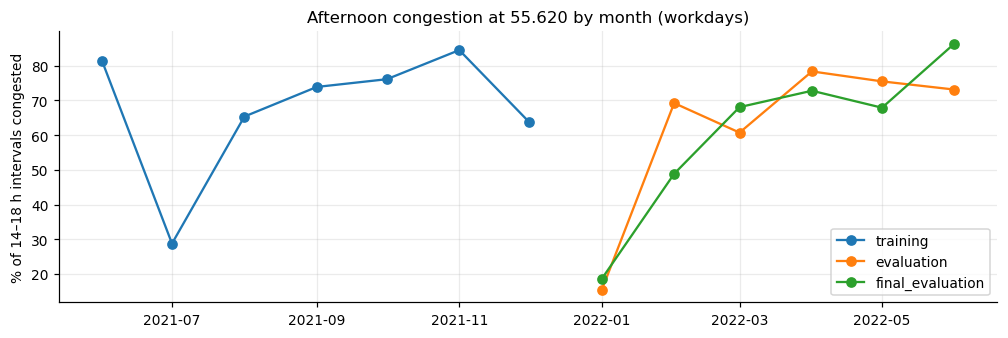

In [9]:
# distribution shift: afternoon congestion by month in 2021 (training) vs 2022 (evaluation files)
fig, ax = plt.subplots(figsize=(11, 3.2))
for s in SPLITS:
    x = wide_obs[s]; tod = (x.index - pd.Timedelta(minutes=5)).hour
    dt = tp.day_type(pd.Series(x.index, index=x.index))
    x = x[(tod >= 14) & (tod < 18) & (dt == "workday")]
    c = pd.Series(reg.proba(TARGET_P, x[f"q_{TARGET_P}"], x[f"v_{TARGET_P}"]) >= 0.5, index=x.index)
    m = c.groupby(x.index.to_period("M")).mean() * 100
    ax.plot(m.index.to_timestamp(), m.values, "o-", label=s)
ax.set(ylabel="% of 14–18 h intervals congested", title="Afternoon congestion at 55.620 by month (workdays)"); ax.legend()
save(fig, "A1_congestion_by_month"); plt.show()

## 3. Features (all day, across midnight) and splits
Same features as notebook 01 plus: density `k_p*_lag0`, regime probability `r_p*_lag0` (P(congested) at time t for each portal,
from the train-split regime model), cyclic time of day. Targets `y_q_p*` = flow 15 min ahead (un-filled, hindsight cleaning).
`y_v_p*` and `y_reg_q_p*` (regime of the target) are **evaluation labels only**, never inputs.

**Inputs come from the causal cleaning, targets from the hindsight cleaning.** The historical average `hist_q_p*` is recomputed per split:

| table | used for | hist profile from | own target excluded? |
|---|---|---|---|
| `features_train` | fitting, CV, early stopping | train split (days < 2021-11-15) | yes — out-of-fold (other weeks) |
| `features_val` | validation / model choice | train split | not in the profile |
| `features_full` | final refit on all 2021 | all 2021 | yes — out-of-fold (other weeks) |
| `features_evaluation`, `features_final_evaluation` | test | all 2021 | not in the profile |

In [10]:
wide = {s: tp.to_wide(p) for s, p in portal_c.items()}                          # causal, gap-filled -> inputs
wide_flags = {s: tp.to_wide(p, observed=True) for s, p in portal_c.items()}     # causal, un-filled  -> *_filled flags
VAL_TS = pd.Timestamp(VAL_START)
W_all = wide_obs["training"]; W_trs = W_all[W_all.index <= VAL_TS]              # bins of days before VAL_START
prof_trs = tp.fit_profile(W_trs); prof_trs.to_pickle(OUT / "hist_profile_train_split.pkl")   # stage 1: train/val rows
prof_all = tp.fit_profile(W_all); prof_all.to_pickle(OUT / "hist_profile_training.pkl")      # stage 2: full refit, 2022
feats = {}
for s in SPLITS:
    F = tp.build_features(wide[s], prof_all, horizon_min=HORIZON_MIN, res_min=RES_MIN, target_window=None,
                          wide_obs=wide_obs[s], wide_flags=wide_flags[s], continuous=True, extra=True)
    feats[s] = tp.add_regime_features(F, reg)
F = feats["training"]; HCOLS = [c for c in F.columns if c.startswith("hist_")]
t_target = F.index + pd.Timedelta(minutes=HORIZON_MIN)

def with_hist(D, W_fit, oof):
    D = D.copy(); D[HCOLS] = tp.hist_features(D, W_fit, HORIZON_MIN, oof_folds=oof)[HCOLS]; return D

parts = {"train": with_hist(F[t_target <= VAL_TS], W_trs, 5),      # target before validation starts; out-of-fold profile
         "val": with_hist(F[F.index >= VAL_TS], W_trs, 0),         # profile from the train split only
         "full": with_hist(F, W_all, 5),                           # final refit on all 2021; out-of-fold profile
         "evaluation": with_hist(feats["evaluation"], W_all, 0),
         "final_evaluation": with_hist(feats["final_evaluation"], W_all, 0)}
for n, d in parts.items(): d.to_pickle(OUT / f"features_{n}.pkl")
X_COLS = [c for c in F.columns if not c.startswith("y_")]
pd.DataFrame({n: {"days": (d.index - pd.Timedelta(minutes=RES_MIN)).normalize().nunique(), "rows": len(d), "features": len(X_COLS),
                  "target missing (55.620)": int(d["y_q_p55620"].isna().sum()),
                  "congested targets (55.620)": int((d["y_reg_q_p55620"] == 1).sum()),
                  "morning-benchmark rows": int(d.tod_target_min.between(450, 510).sum())}
              for n, d in parts.items()})

,train,val,full,evaluation,final_evaluation
days,167,48,214,80,101
rows,48093,13537,61632,23040,29088
features,150,150,150,150,150
target missing (55.620),2692,119,2811,1216,2181
congested targets (55.620),4981,1426,6407,2177,2487
morning-benchmark rows,2171,611,2782,1040,1313


In [11]:
# quick sanity check: baselines on validation, all day vs the morning benchmark
va = parts["val"]; y = va["y_q_p55620"]; ok = y.notna()
def rmse(a, b): m = a.notna() & b.notna(); return float(np.sqrt(((a[m] - b[m]) ** 2).mean()))
pers = va["q_p55620_lag0"].fillna(va["hist_q_p55620"]); hist = va["hist_q_p55620"]
peak = va.tod_target_min.between(450, 510)
pd.DataFrame({"all day": [rmse(y, pers), rmse(y, hist)], "07:30–08:30": [rmse(y[peak], pers[peak]), rmse(y[peak], hist[peak])]},
             index=["persistence", "historical average"]).round(0)

,all day,07:30–08:30
persistence,382.0,355.0
historical average,452.0,541.0


## 4. Leakage checks
Data leakage = the model sees, during training or validation, information it would not have at prediction time in real use.
Four checks:

1. **Future-perturbation test of the cleaning.** Take 4 days of raw data, cut at a random time, and either *delete* everything after the
   cut or *triple* the flows after it. Then clean again and compare every portal value stamped **before** the cut. A causal pipeline
   must give identical values; any difference means the past depends on the future.
2. **Historical average, in-sample vs honest.** How much better does the historical-average baseline look on validation when its
   profile includes the validation days (the old pipeline) than when it only uses the train split?
3. **Out-of-fold check.** Changing a training target must not change that row's own `hist` input.
4. **Structural checks.** No `y_` column among the inputs; no training target inside the validation period; the 2022 files share no
   days with 2021; every fitted statistic uses days before 2021-11-15 only.

In [12]:
# 1. future-perturbation test (causal = what the model sees; hindsight = targets only)
VARS = ["flow_vph", "speed_kmh", "flow_vph_obs", "speed_kmh_obs"]
def portal_vals(raw, causal):
    lg, _ = tp.clean_lane_data(raw, lane_stats, causal=causal)
    return tp.aggregate_portal(lg, lane_stats, res=f"{RES_MIN}min").set_index(["portal_km", "ts"])[VARS]
base = {c: portal_vals(raw_chk, c) for c in (True, False)}
rng = np.random.default_rng(1); rows = []
for k in range(40):
    d = days_chk[rng.integers(1, len(days_chk))]; m = int(rng.integers(0, 1440 - 30)); cut = pd.Timestamp(d) + pd.Timedelta(minutes=m)
    after = (raw_chk["date"] > d) | ((raw_chk["date"] == d) & (raw_chk["minute"] >= m))
    for how in ("delete", "x3"):
        pert = raw_chk[~after] if how == "delete" else raw_chk.assign(flow=raw_chk["flow"].where(~after, raw_chk["flow"] * 3))
        for causal in (True, False):
            a = base[causal]; a = a[a.index.get_level_values("ts") <= cut]
            b = portal_vals(pert, causal).reindex(a.index)
            n = int((~np.isclose(a.to_numpy(float), b.to_numpy(float), equal_nan=True)).sum())
            rows.append({"cleaning": "causal (inputs)" if causal else "hindsight (targets)", "perturbation": how,
                         "raw rows after cut": int(after.sum()), "past values compared": a.size, "past values changed": n})
pt = pd.DataFrame(rows)
pt.groupby(["cleaning", "perturbation"]).agg(tests=("past values changed", "size"),
    tests_with_change=("past values changed", lambda x: int((x > 0).sum())), values_changed=("past values changed", "sum"),
    mean_raw_rows_perturbed=("raw rows after cut", "mean"), mean_past_values_compared=("past values compared", "mean")).round(0)

tests  tests_with_change  values_changed  \
cleaning            perturbation                                             
causal (inputs)     delete           40                  0               0   
                    x3               40                  0               0   
hindsight (targets) delete           40                 10              72   
                    x3               40                  8              40   

                                  mean_raw_rows_perturbed  \
cleaning            perturbation                            
causal (inputs)     delete                        53392.0   
                    x3                            53392.0   
hindsight (targets) delete                        53392.0   
                    x3                            53392.0   

                                  mean_past_values_compared  
cleaning            perturbation                             
causal (inputs)     delete                          22940.0  
                    x3                              22940.0  
hindsight (targets) delete                          22940.0  
                    x3                              22940.0

In [13]:
# 2. historical-average baseline on validation: profile incl. the validation days (old, leaky) vs train split only
y = va["y_q_p55620"]
dt = tp.day_type(pd.Series(va.index, index=va.index)); key = pd.MultiIndex.from_arrays([dt, va["tod_target_min"]])
leaky = pd.Series(prof_all["q_p55620"].reindex(key).to_numpy(), index=va.index)
tr = parts["train"]; ytr = tr["y_q_p55620"]
dtt = tp.day_type(pd.Series(tr.index, index=tr.index)); ktr = pd.MultiIndex.from_arrays([dtt, tr["tod_target_min"]])
insample = pd.Series(prof_trs["q_p55620"].reindex(ktr).to_numpy(), index=tr.index)
pd.DataFrame({"RMSE (veh/h)": [rmse(y, leaky), rmse(y, va["hist_q_p55620"]), rmse(ytr, insample), rmse(ytr, tr["hist_q_p55620"])]},
             index=["validation — profile incl. validation days (old)", "validation — train-split profile (now)",
                    "training rows — in-sample profile", "training rows — out-of-fold profile (now)"]).round(1)

,RMSE (veh/h)
validation — profile incl. validation days (old),430.7
validation — train-split profile (now),452.1
training rows — in-sample profile,406.6
training rows — out-of-fold profile (now),410.6


In [14]:
# 3. out-of-fold check: +5000 veh/h on 20 random training targets must leave those rows' own hist input unchanged
rng = np.random.default_rng(2); idx = rng.choice(np.flatnonzero(tr["y_q_p55620"].notna()), 20, replace=False)
W2 = W_trs.copy(); tt = tr.index[idx] + pd.Timedelta(minutes=HORIZON_MIN); W2.loc[tt, "q_p55620"] += 5000
h_new = tp.hist_features(tr.iloc[idx], W2, HORIZON_MIN, oof_folds=5)["hist_q_p55620"]
h_plain = tp.hist_features(tr.iloc[idx], W2, HORIZON_MIN, oof_folds=0)["hist_q_p55620"]
pd.Series({"rows tested": len(idx),
           "own hist changed — out-of-fold (now)": int((~np.isclose(h_new, tr["hist_q_p55620"].iloc[idx])).sum()),
           "own hist changed — plain in-sample profile": int((~np.isclose(h_plain, prof_trs["q_p55620"].reindex(ktr[idx]).to_numpy())).sum())})

rows tested                                   20
own hist changed — out-of-fold (now)           0
own hist changed — plain in-sample profile    20
dtype: int64

In [15]:
# 4. structural checks
d_of = lambda ix: set((ix - pd.Timedelta(minutes=RES_MIN)).normalize())
checks = {
    "no y_ column among the inputs": not any(c.startswith("y_") for c in X_COLS),
    "last training target <= validation start": bool((parts["train"].index + pd.Timedelta(minutes=HORIZON_MIN)).max() <= VAL_TS),
    "first validation row >= validation start": bool(parts["val"].index.min() >= VAL_TS),
    "2022 files share no days with 2021": not (d_of(wide_obs["training"].index) & (d_of(wide_obs["evaluation"].index) | d_of(wide_obs["final_evaluation"].index))),
    "evaluation and final_evaluation share no days": not (d_of(wide_obs["evaluation"].index) & d_of(wide_obs["final_evaluation"].index)),
    "profile (stage 1) uses days < validation start only": bool(W_trs.index.max() <= VAL_TS),
    "regime model and lane stats fitted on days < validation start": True,   # by construction in sections 1–2 (train split passed in)
}
pd.Series(checks, name="passed")

no y_ column among the inputs                                    True
last training target <= validation start                         True
first validation row >= validation start                         True
2022 files share no days with 2021                               True
evaluation and final_evaluation share no days                    True
profile (stage 1) uses days < validation start only              True
regime model and lane stats fitted on days < validation start    True
Name: passed, dtype: bool

**Result.** The causal cleaning passes the perturbation test: **0 of 80** perturbations changed a single past value. The hindsight
cleaning fails it (**18 of 80** changed past values, mostly around night-time gaps) — which is why it is only used for targets.
About 10 % of the 5-min input values differ between the two cleanings, almost all at night (24–37 % of bins between 00:00 and 05:00,
0.4–4 % between 07:00 and 22:00): in real time a silent lane cannot be told apart from an empty one until enough vehicles are "missing".
The old pipeline's historical profile contained the validation days, which made the historical-average baseline look 21 veh/h
better on validation than it is (431 vs 452 veh/h); now validation rows only see the train split, and training rows see an
out-of-fold average.
Remaining, *not* a leak but a caveat for the report: several design choices (augmentation, A4 fixes, A5 architectures) were compared
on the `evaluation` file, so that file is partly a model-selection set; only `final_evaluation` (used once) is a clean test.

**Next:** `A2_allday_modelling.ipynb` — single vs regime-split models, evaluated all day, on the 07:30–08:30 benchmark and per regime.